In [66]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pandas.api.types import is_numeric_dtype
import warnings
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree  import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, VotingClassifier, GradientBoostingClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import BernoulliNB
from lightgbm import LGBMClassifier
from sklearn.feature_selection import RFE
import itertools
from xgboost import XGBClassifier
from tabulate import tabulate

In [49]:
train_data = pd.read_csv("Train_data.csv")
test_data = pd.read_csv("Test_data.csv")

In [26]:
print("Training Data Shape:", train_data.shape)

Training Data Shape: (25192, 42)


In [17]:
train_data.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


In [18]:
train_data.tail()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
25187,0,tcp,exec,RSTO,0,0,0,0,0,0,...,7,0.03,0.06,0.00,0.00,0.0,0.0,1.0,1.0,anomaly
25188,0,tcp,ftp_data,SF,334,0,0,0,0,0,...,39,1.00,0.00,1.00,0.18,0.0,0.0,0.0,0.0,anomaly
25189,0,tcp,private,REJ,0,0,0,0,0,0,...,13,0.05,0.07,0.00,0.00,0.0,0.0,1.0,1.0,anomaly
25190,0,tcp,nnsp,S0,0,0,0,0,0,0,...,20,0.08,0.06,0.00,0.00,1.0,1.0,0.0,0.0,anomaly
25191,0,tcp,finger,S0,0,0,0,0,0,0,...,49,0.19,0.03,0.01,0.00,1.0,1.0,0.0,0.0,anomaly


In [24]:
train_data.isnull().sum()

duration                       0
protocol_type                  0
service                        0
flag                           0
src_bytes                      0
dst_bytes                      0
land                           0
wrong_fragment                 0
urgent                         0
hot                            0
num_failed_logins              0
logged_in                      0
num_compromised                0
root_shell                     0
su_attempted                   0
num_root                       0
num_file_creations             0
num_shells                     0
num_access_files               0
num_outbound_cmds              0
is_host_login                  0
is_guest_login                 0
count                          0
srv_count                      0
serror_rate                    0
srv_serror_rate                0
rerror_rate                    0
srv_rerror_rate                0
same_srv_rate                  0
diff_srv_rate                  0
srv_diff_h

In [47]:
print(train_data.dtypes)

duration                         int64
protocol_type                   object
service                         object
flag                            object
src_bytes                        int64
dst_bytes                        int64
land                             int64
wrong_fragment                   int64
urgent                           int64
hot                              int64
num_failed_logins                int64
logged_in                        int64
num_compromised                  int64
root_shell                       int64
su_attempted                     int64
num_root                         int64
num_file_creations               int64
num_shells                       int64
num_access_files                 int64
num_outbound_cmds                int64
is_host_login                    int64
is_guest_login                   int64
count                            int64
srv_count                        int64
serror_rate                    float64
srv_serror_rate          

In [30]:
print(f"Number of Duplicate rows: {train_data.duplicated().sum()}")

Number of Duplicate rows: 0


<Axes: xlabel='class', ylabel='count'>

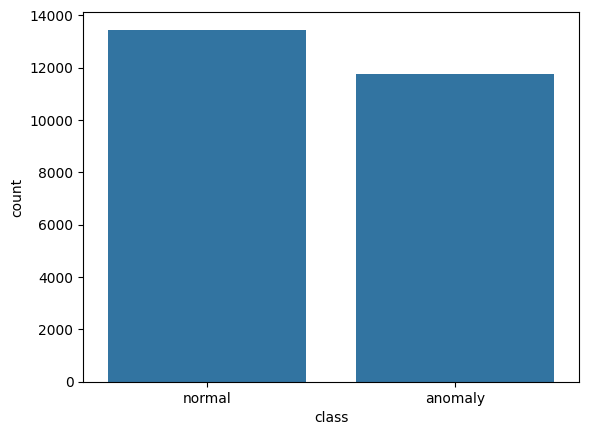

In [67]:
sns.countplot(x=train_data['class'])

In [50]:
print('Class distribution Training set:')
print(train_data['class'].value_counts())

Class distribution Training set:
class
normal     13449
anomaly    11743
Name: count, dtype: int64


In [53]:
train_encoded = train_data.copy()
test_encoded = test_data.copy()

In [54]:
def le(df):
    for col in df.columns:
        if df[col].dtype == 'object':
                label_encoder = LabelEncoder()
                df[col] = label_encoder.fit_transform(df[col])

le(train_encoded)
le(test_encoded)
     
train_encoded.drop(['num_outbound_cmds'], axis=1, inplace=True)
test_encoded.drop(['num_outbound_cmds'], axis=1, inplace=True)

In [55]:
train_encoded.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,1,19,9,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,1
1,0,2,41,9,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,1
2,0,1,46,5,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,0
3,0,1,22,9,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,1
4,0,1,22,9,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1


In [56]:
X_train = train_encoded.drop(['class'], axis=1)
Y_train = train_encoded['class']
     

rfc = RandomForestClassifier()

rfe = RFE(rfc, n_features_to_select=10)
rfe = rfe.fit(X_train, Y_train)

feature_map = [(i, v) for i, v in itertools.zip_longest(rfe.get_support(), X_train.columns)]
selected_features = [v for i, v in feature_map if i==True]

selected_features

['protocol_type',
 'service',
 'flag',
 'src_bytes',
 'dst_bytes',
 'count',
 'same_srv_rate',
 'diff_srv_rate',
 'dst_host_srv_count',
 'dst_host_same_srv_rate']

In [57]:
X_train = X_train[selected_features]

In [60]:
scale = StandardScaler()
X_train = scale.fit_transform(X_train)
test_encoded = scale.fit_transform(test_encoded)

In [61]:
x_train, x_test, y_train, y_test = train_test_split(X_train, Y_train, train_size=0.70, random_state=2)

In [62]:
x_train.shape

(17634, 10)

In [63]:
y_train.shape

(17634,)

In [68]:
y_test.shape

(7558,)

In [69]:
import time

In [79]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [80]:
from sklearn.tree import DecisionTreeClassifier
  
clfd = DecisionTreeClassifier(criterion ="entropy", max_depth = 4)
start_time = time.time()
clfd.fit(x_train, y_train.values.ravel())
end_time = time.time()
print("Training time: ", end_time-start_time)

Training time:  0.02879619598388672


In [81]:
start_time = time.time()
y_test_pred = clfd.predict(x_train)
end_time = time.time()
print("Testing time: ", end_time-start_time)

Testing time:  0.002695322036743164


In [82]:
def objective(trial):
    dt_max_depth = trial.suggest_int('dt_max_depth', 2, 32, log=False)
    dt_max_features = trial.suggest_int('dt_max_features', 2, 10, log=False)
    classifier_obj = DecisionTreeClassifier(max_features = dt_max_features, max_depth = dt_max_depth)
    classifier_obj.fit(x_train, y_train)
    accuracy = classifier_obj.score(x_test, y_test)
    return accuracy

In [83]:
study_dt = optuna.create_study(direction='maximize')
study_dt.optimize(objective, n_trials=30)
print(study_dt.best_trial)

FrozenTrial(number=16, state=1, values=[0.9953691452765282], datetime_start=datetime.datetime(2025, 5, 18, 17, 47, 53, 210947), datetime_complete=datetime.datetime(2025, 5, 18, 17, 47, 53, 231030), params={'dt_max_depth': 20, 'dt_max_features': 4}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'dt_max_depth': IntDistribution(high=32, log=False, low=2, step=1), 'dt_max_features': IntDistribution(high=10, log=False, low=2, step=1)}, trial_id=16, value=None)


In [84]:
dt = DecisionTreeClassifier(max_features = study_dt.best_trial.params['dt_max_features'], max_depth = study_dt.best_trial.params['dt_max_depth'])
dt.fit(x_train, y_train)

dt_train, dt_test = dt.score(x_train, y_train), dt.score(x_test, y_test)

print(f"Train Score: {dt_train}")
print(f"Test Score: {dt_test}")

Train Score: 1.0
Test Score: 0.9937814236570521


In [86]:
SEED = 42

# Decision Tree Classifier Performance Evaluation
dtc = DecisionTreeClassifier()

from sklearn.model_selection import cross_val_score

scores = {}
for scorer in ['precision', 'recall']:
    scores[scorer] = cross_val_score(dtc, x_train, y_train, cv=10, scoring=scorer)

print("***** Decision Tree Model Validation *****")
for scorer in ['precision', 'recall']:
    mean = round(np.mean(scores[scorer]) * 100, 2)
    stdev = round(np.std(scores[scorer]) * 100, 2)
    print(f"Mean {scorer.capitalize()}: {mean}% ± {stdev}%\n")
     


***** Decision Tree Model Validation *****
Mean Precision: 99.51% ± 0.18%

Mean Recall: 99.49% ± 0.16%



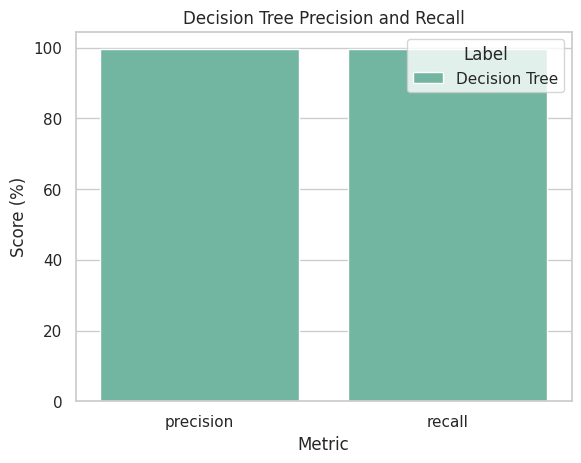

In [91]:
sns.set_theme(style="whitegrid")

# Reshaping the data for Seaborn and renaming the index column
scores_melted = scores_df.reset_index().rename(columns={'index': 'Metric'}).melt(id_vars='Metric', var_name='Label', value_name='Score')

# Plot using Seaborn with hue for distinct colors
ax = sns.barplot(data=scores_melted, x='Metric', y='Score', hue='Label', palette="Set2")
ax.set_title("Decision Tree Precision and Recall")
ax.set_ylabel("Score (%)")
plt.show()


In [92]:
# Train the model
dtc.fit(x_train, y_train)

DecisionTreeClassifier()

In [93]:
# Make predictions
y_pred = dtc.predict(x_test)
print("Predictions complete.")

Predictions complete.


In [94]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score

# Display the evaluation metrics
def line(name, sym="*"):
    return sym * (25 - len(name) // 2)

target_names = ["normal", "anomaly"]
print(line("Decision Tree"), "Decision Tree Model Testing", line("Decision Tree"))
print(confusion_matrix(y_test, y_pred))
print(line("Decision Tree", '-'))
print(classification_report(y_test, y_pred, target_names=target_names))


******************* Decision Tree Model Testing *******************
[[3484   14]
 [  26 4034]]
-------------------
              precision    recall  f1-score   support

      normal       0.99      1.00      0.99      3498
     anomaly       1.00      0.99      1.00      4060

    accuracy                           0.99      7558
   macro avg       0.99      0.99      0.99      7558
weighted avg       0.99      0.99      0.99      7558



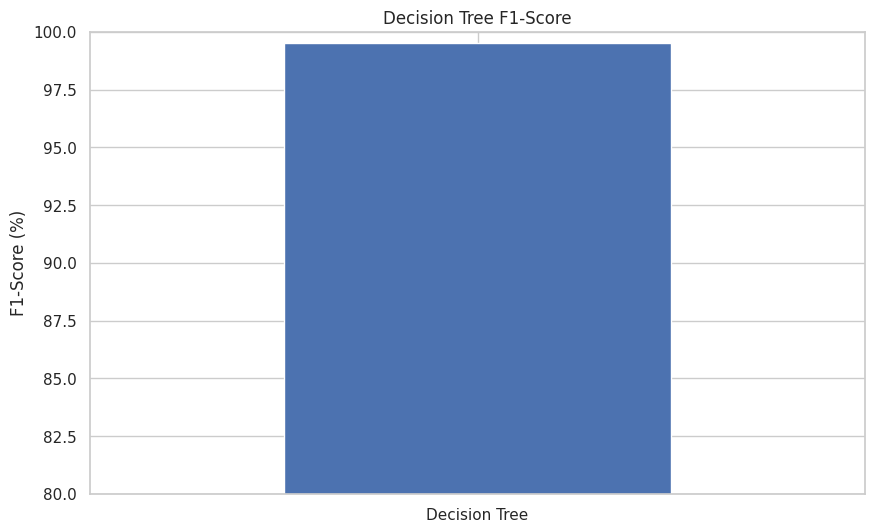

In [95]:
# Calculate F1-score for the Decision Tree model
f1 = f1_score(y_test, y_pred) * 100

# Create a DataFrame for plotting
f1_df = pd.DataFrame({"F1-score": [f1]}, index=["Decision Tree"])

# Plot the F1-score as a bar chart
f1_df.plot(kind="bar", ylim=[80, 100], figsize=(10, 6), rot=0, legend=False)

# Adding title and labels
plt.title("Decision Tree F1-Score")
plt.ylabel("F1-Score (%)")
plt.show()

In [97]:
import joblib

# Save the trained model to a file
joblib.dump(dtc, "decision_tree_model.pkl")
print("Model saved successfully!")


Model saved successfully!
